(differential-expression-tutorial)=
# Differential expression per cell type

This page runs a pseudobulk differential-expression analysis from cells to results:
it simulates single cells from six donors, each sampled before and after a
stimulation, pools them into a cube of counts per sample and cell type, saves the cube
and opens it again, tests the stimulation in every cell type with limma-voom, and then
follows one result back through its provenance record to the profiles of the cube that
produced it. Every step of the test matches limma and edgeR, as the
[Validation](validation.md#differential-expression) page shows.

Pooling the cells of each sample first makes the sample, not the cell, the unit of
replication: cells from one donor are not independent observations, and a test that
treated them as such would find differences that do not hold across donors.

In [1]:
import json

import matplotlib.pyplot as plt
import numba
import numpy as np

from cytepool.cube import from_cells
from cytepool.design import Design
from cytepool.differential_expression import limma_voom
from cytepool.io import read_cube, write_cube
from cytepool.table import Table

print("numpy", np.__version__, "and numba", numba.__version__)

numpy 2.5.4 and numba 0.68.0


## Simulate cells from six donors

Six donors (D1 to D6) each give a control and a stimulated sample: twelve samples in a
paired design. Every sample holds four cell types in different numbers: many T cells,
fewer B and NK cells, and few dendritic cells (DC). Donor D1 has almost no NK cells.

Each cell type has its own expression profile over 1,500 genes. A donor shifts every
gene a little, in all its samples alike, and the stimulation changes 150 genes of each
cell type, a different set for each, by 0.8 to 2 on the log2 scale. Cells differ in
depth, 1,500 to 6,000 reads, and in their expression around the profile.

In [2]:
rng = np.random.default_rng(20261025)
donors = [f"D{d}" for d in range(1, 7)]
sample_table = Table(
    {
        "sample_id": [f"{d}_{c}" for d in donors for c in ("ctrl", "stim")],
        "donor": np.repeat(donors, 2),
        "condition": np.tile(["ctrl", "stim"], 6),
    }
)
n_genes = 1_500
genes = np.array([f"gene_{g:04d}" for g in range(n_genes)])
mean_cells = {"T": 150, "B": 60, "NK": 35, "DC": 8}
donor_shift = {d: rng.normal(0.0, 0.3, n_genes) for d in donors}

true_log2_fc = {}
blocks, cell_sample, cell_type = [], [], []
for name, mean in mean_cells.items():
    profile = rng.normal(0.0, 1.8, n_genes)
    changed = rng.choice(n_genes, 150, replace=False)
    effect = np.zeros(n_genes)
    effect[changed] = rng.choice([-1, 1], 150) * rng.uniform(0.8, 2.0, 150)
    true_log2_fc[name] = effect
    for sample_id, donor, condition in zip(
        sample_table["sample_id"], sample_table["donor"], sample_table["condition"]
    ):
        n = rng.poisson(mean) if not (name == "NK" and donor == "D1") else 3
        log2_mean = profile + donor_shift[donor] + effect * (condition == "stim")
        proportion = 2.0**log2_mean / np.sum(2.0**log2_mean)
        depth = rng.uniform(1_500, 6_000, (n, 1))
        rate = rng.gamma(4.0, 0.25, (n, n_genes)) * depth * proportion
        blocks.append(rng.poisson(rate))
        cell_sample += [sample_id] * n
        cell_type += [name] * n
counts = np.vstack(blocks)
print(f"{counts.shape[0]:,} cells x {counts.shape[1]:,} genes")

2,987 cells x 1,500 genes


## Pool the cells into a cube

[`from_cells`](/api/cubes.html#cytepool.cube.from_cells) sums the counts of the cells of
every sample and cell type into a cube: one pseudobulk profile per sample and cell
type, with the number of cells behind each. The sample table travels with the cube,
and so does a provenance record: how the cube was built, and a record of where the
cells came from, `source`, which the caller gives and CytePool keeps as it is.

In [3]:
cube = from_cells(
    counts,
    samples=cell_sample,
    groups=cell_type,
    sample_table=sample_table,
    features=genes,
    layers="counts",
    source={"dataset": "simulated study of six donors", "seed": 20261025},
)
print(cube)
print()
groups = cube.groups["group_id"].tolist()
print("cells per sample and cell type:")
print(f"{'':<9}" + "".join(f"{group:>6}" for group in groups))
for row, sample_id in enumerate(cube.samples["sample_id"]):
    print(f"{sample_id:<9}" + "".join(f"{n:>6}" for n in cube.n_cells[row]))

Cube with 12 samples x 4 groups x 1,500 features
  layers: counts (uint32)
  filled: 48 of 48 sample x group entries have cells (100.0%)
  samples: sample_id, donor, condition
  groups: group_id
  features: feature_id

cells per sample and cell type:
              B    DC    NK     T
D1_ctrl      57     7     3   155
D1_stim      54    12     3   165
D2_ctrl      56     8    29   140
D2_stim      56     9    23   174
D3_ctrl      56     8    29   144
D3_stim      60     5    35   170
D4_ctrl      58     6    24   138
D4_stim      61    10    41   178
D5_ctrl      58     7    45   152
D5_stim      55    15    35   138
D6_ctrl      53    14    33   156
D6_stim      59    10    38   145


## Save the cube and open it again

[`write_cube`](/api/cube_files.html#cytepool.io.write_cube) saves the cube as a Zarr
v3 store, and [`read_cube`](/api/cube_files.html#cytepool.io.read_cube) opens it
without reading its counts: the layer stays on disk and is read one cell type at a
time, when the analysis needs it. A cube far larger than memory can therefore be
analysed group by group.

A cube's fingerprint names its values: its tables, cell numbers and every group of
every layer. The file stores the digests the fingerprint is built from, so the opened
cube knows its fingerprint without reading its counts, and it is the in-memory cube's.

In [4]:
write_cube(cube, "pbmc.cube.zarr", overwrite=True)
opened = read_cube("pbmc.cube.zarr")
print(opened)
print("same fingerprint:", opened.fingerprint() == cube.fingerprint())

Cube with 12 samples x 4 groups x 1,500 features
  layers: counts (uint32, lazy)
  filled: 48 of 48 sample x group entries have cells (100.0%)
  samples: sample_id, donor, condition
  groups: group_id
  features: feature_id
same fingerprint: True


## Describe the design

The design is built from the cube's sample table. `~ donor + condition` compares the
two samples of each donor, so differences between donors do not count as noise. The
named contrast `stim_vs_ctrl` is the coefficient of the stimulation.
[`limma_voom`](/api/differential_expression.html#cytepool.differential_expression.limma_voom)
matches the design's samples to the cube's by `sample_id`, never by position.

In [5]:
design = Design(
    opened.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
print(design)
print(design.check())

Design: 12 samples x 7 columns, formula '~ donor + condition'
  columns: (Intercept), donorD2, donorD3, donorD4, donorD5, donorD6, conditionstim
  contrasts: stim_vs_ctrl
Design check: 12 samples, 7 columns, rank 7, 5 residual degrees of freedom; no problems found.


## Test every cell type

`limma_voom` runs the limma-voom workflow of the limma and edgeR User's Guides in each
cell type: it leaves out the samples with fewer than 10 cells (`min_cells`) and keeps
the rows of the design for the others, filters genes by edgeR's `filterByExpr` rule
with that design, computes TMM normalization factors, gives every observation a voom
precision weight, fits a weighted linear model to every gene, and moderates the
contrast by empirical Bayes. voom smooths its mean-variance trend with a span chosen
from the number of genes tested in each cell type, as limma's voom does since limma
3.66; `span=` fixes it. One cell type is in memory at a time.

In [6]:
result = limma_voom(opened, design)
print(result)

DifferentialExpressionResult (limma_voom): 4 groups, 3 fitted; 1 contrast: stim_vs_ctrl
  B: 12 samples, 1447 features
  DC: not fitted (no_residual_df)
  NK: 10 samples, 1353 features
  T: 12 samples, 1495 features


The summary has one row per cell type. The dendritic cells were not fitted: too few
of their samples have 10 cells or more, and the design, with an effect for each of
their donors and the stimulation, fits those samples exactly, which leaves no
residual degrees of freedom to estimate a variance from. The status and reason say
so, and the other cell types are fitted. The NK cells were fitted without donor D1's
two samples.

In [7]:
summary = result.summary
for row in range(len(summary)):
    print(
        f"{summary['group_id'][row]:<4}{summary['status'][row]:<16}"
        f"samples used: {summary['n_samples_used'][row]:>2} of 12, "
        f"genes tested: {summary['n_features_tested'][row]:>5}, "
        f"residual df: {summary['df_residual'][row]:.0f}"
    )
print()
print(summary["reason"][summary["group_id"] == "DC"][0])

B   fitted          samples used: 12 of 12, genes tested:  1447, residual df: 5
DC  no_residual_df  samples used:  5 of 12, genes tested:     0, residual df: 0
NK  fitted          samples used: 10 of 12, genes tested:  1353, residual df: 4
T   fitted          samples used: 12 of 12, genes tested:  1495, residual df: 5

no residual degrees of freedom: the design has rank 5 on the 5 samples left, so it fits them exactly and no variance can be estimated


## A rank-deficient group

Without donor D1, the NK cells' rows of the design no longer separate every column:
D1 is the reference level of `donor`, and the column of the last donor, `donorD6`,
equals the intercept minus the other donor columns over the remaining samples. Such a
group is fitted on the columns that R's QR decomposition keeps, as limma does, and a
contrast is tested only if those samples can estimate it. The stimulation compares the
two samples of each remaining donor, so it is estimable; a comparison of donor D2
with donor D1 is not, and is reported, not computed. (limma would compute it from the
kept columns, where it means D2 against D6.)

In [8]:
nk = next(g for g in result.provenance["groups"] if g["group_id"] == "NK")
print("left out:", nk["left_out"])
print("aliased columns:", nk["aliased_columns"])

donors_compared = limma_voom(
    opened, design, groups="NK", contrasts={"D2_vs_D1": "donorD2"}
)
print(donors_compared.summary["status"][0])
print(donors_compared.provenance["groups"][0]["not_estimable"]["D2_vs_D1"])

left out: {'D1_ctrl': '3 cells, fewer than min_cells (10)', 'D1_stim': '3 cells, fewer than min_cells (10)'}
aliased columns: ['donorD6']
no_estimable_contrast
not estimable from the samples of this group, which cannot separate the effects it depends on: donorD6 = (Intercept) - donorD2 - donorD3 - donorD4 - donorD5


## A result table

Each cell type and contrast has a table of the tested genes in the cube's gene order,
with the columns of limma's `topTable`. Here are the T-cell genes with the smallest
p-values for the stimulation.

In [9]:
table = result.table("T", "stim_vs_ctrl")
columns = ["log2_fold_change", "average_log2_cpm", "t", "adjusted_p_value"]
print(f"{'gene':<10}" + "".join(f"{column:>18}" for column in columns))
for row in np.argsort(table["p_value"])[:8]:
    values = "".join(f"{table[column][row]:>18.3g}" for column in columns)
    print(f"{table['feature_id'][row]:<10}{values}")

gene        log2_fold_change  average_log2_cpm                 t  adjusted_p_value
gene_1458               1.95              13.2              53.6         1.49e-163
gene_0090               2.11              10.3              44.4         9.93e-140
gene_0188               1.87              11.1              43.3         9.52e-137
gene_0069               1.68              11.9              42.8         1.89e-135
gene_1305              -1.79              11.1               -42         3.46e-133
gene_0814               1.57                12              40.3         1.89e-128
gene_0502               1.71                11              39.9         4.26e-127
gene_0530               1.88              10.3              39.6          2.3e-126


The simulation knows which genes the stimulation changed. At a 5% false discovery
rate, few discoveries should be false, and most changed genes that pass the filter
should be found.

In [10]:
for group in ("T", "B", "NK"):
    table = result.table(group, "stim_vs_ctrl")
    tested = np.isin(genes, table["feature_id"])
    changed = true_log2_fc[group][tested] != 0
    found = table["adjusted_p_value"] < 0.05
    false_found = np.count_nonzero(found & ~changed)
    print(
        f"{group:<3}: {np.count_nonzero(found & changed)} of {changed.sum()} changed "
        f"genes found; {false_found} of {found.sum()} discoveries false"
    )

T  : 150 of 150 changed genes found; 5 of 155 discoveries false

B  : 145 of 148 changed genes found; 4 of 149 discoveries false


NK : 138 of 143 changed genes found; 6 of 144 discoveries false


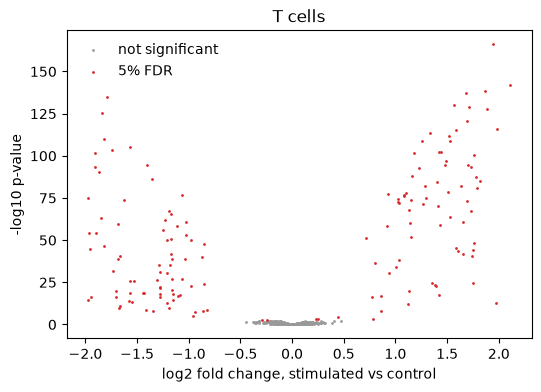

In [11]:
table = result.table("T", "stim_vs_ctrl")
significant = table["adjusted_p_value"] < 0.05
figure, axes = plt.subplots(figsize=(6, 4), dpi=100)
axes.scatter(
    table["log2_fold_change"][~significant],
    -np.log10(table["p_value"][~significant]),
    s=4,
    color="0.6",
    linewidths=0,
    label="not significant",
)
axes.scatter(
    table["log2_fold_change"][significant],
    -np.log10(table["p_value"][significant]),
    s=4,
    color="tab:red",
    linewidths=0,
    label="5% FDR",
)
axes.set_xlabel("log2 fold change, stimulated vs control")
axes.set_ylabel("-log10 p-value")
axes.set_title("T cells")
axes.legend(frameon=False)
plt.show()

## Trace a result back to the cube

The result carries a provenance record, plain JSON, that says what produced every
number: the method and settings; the CytePool, numpy, numba and Python versions; the
cube, by its fingerprint, the digests of its parts and its own provenance; the design,
with the values of its variables for every sample and the weights of every contrast;
and, for every cell type, the samples that entered its fit, in the order they were
fitted, those left out with the reason, and the span of its voom trend.

In [12]:
record = result.provenance
print("method:", record["method"], "| versions of:", ", ".join(record["versions"]))
print("cube fingerprint:", record["cube"]["fingerprint"])
# The settings that decide which samples and genes enter each fit, and how.
chosen = ("min_cells", "expression_filter", "normalization", "span", "robust")
print(json.dumps({key: record["settings"][key] for key in chosen}))
t_cells = next(g for g in record["groups"] if g["group_id"] == "T")
print("T-cell samples:", t_cells["samples"])
print(f"T-cell voom span: {t_cells['voom_span']:.3f}")

method: limma_voom | versions of: cytepool, numpy, numba, python
cube fingerprint: sha256:986da97c859afbc5d455bb29c5e403ea5b552f5b1d35cedf48a7bc5259fba397
{"min_cells": 10, "expression_filter": {"min_count": 10.0, "min_total_count": 15.0, "large_n": 10.0, "min_prop": 0.7}, "normalization": "tmm", "span": null, "robust": false}
T-cell samples: ['D1_ctrl', 'D1_stim', 'D2_ctrl', 'D2_stim', 'D3_ctrl', 'D3_stim', 'D4_ctrl', 'D4_stim', 'D5_ctrl', 'D5_stim', 'D6_ctrl', 'D6_stim']
T-cell voom span: 0.526


A number in the T-cell table comes from the counts of the T cells of these twelve
samples, the profiles `(sample, T)` of the cube with that fingerprint: all of their
genes enter the filter, the normalization factors and the voom trend. A cube at hand
is that cube when its fingerprint is the one recorded. For the cube file this needs no
read; `verify_fingerprint()` reads every group whole and checks it against its digest,
which shows that the file still holds what was analysed. The record also keeps the
digest of each group's counts, which identifies the T-cell profiles alone. Those
profiles can then be read back by their ids, and, for example, the library sizes that
entered the fit recomputed from them.

In [13]:
print("fingerprint matches:", opened.fingerprint() == record["cube"]["fingerprint"])
print(
    "verified by reading:", opened.verify_fingerprint() == record["cube"]["fingerprint"]
)
t = opened.groups["group_id"].tolist().index("T")
counts_digests = record["cube"]["digests"]["layers"]["counts"]["groups"]
print("digest of the T-cell counts:", counts_digests[t])
profiles = opened.select(samples=t_cells["samples"], groups="T").layer("counts", "T")
table = result.table("T", "stim_vs_ctrl")
tested = np.isin(opened.features["feature_id"], table["feature_id"])
rows = result.samples.filter(result.samples["group_id"] == "T")
print("profiles:", profiles.shape)
print(
    "library sizes agree:",
    np.array_equal(profiles[:, tested].sum(axis=1), rows["library_size"][rows["used"]]),
)

fingerprint matches: True
verified by reading: True
digest of the T-cell counts: sha256:e133ff04638b37a618fa29894a9232ecc1b3bd9623484e9b28546036cc851096


profiles: (12, 1500)
library sizes agree: True


The cube's own provenance, kept in the record, says how the cube was made, in plain
terms:

In [14]:
print(opened.history())

Source, as the caller recorded it (unresolved: CytePool does not follow its references):
  dataset: "simulated study of six donors"
  seed: 20261025
Built by from_cells (CytePool 0.1.dev24+ge9d6ae2d6.d20261025) from 2,987 cells:
  samples: the rows of sample_table
  groups: the sorted distinct labels
  features: ids given as a sequence
  layers: counts
  normalized values: each cell scaled to a total of 10,000, with library sizes the total count of each cell
References: CytePool resolves none on its own. The source record's references need the tool that wrote them. A fingerprint names a cube without saying where it is: Cube.fingerprint() of a cube at hand says whether it is that cube.
Fingerprint: sha256:986da97c859afbc5d455bb29c5e403ea5b552f5b1d35cedf48a7bc5259fba397


What CytePool can and cannot resolve on its own:

- **It can** go from any number of a result to its cell type, its contrast and its
  gene, to the samples that entered that fit and those left out with the reason, and
  to the cube's profiles of those samples and that cell type, by their ids. It can
  tell whether a cube at hand is the one analysed, by its fingerprint, and check by
  reading it that its values still match their digests. The record also holds the
  design and the settings that the fit used, and how the cube was made: here by
  `from_cells` from the number of cells shown above.
- **It cannot** find the cube from its fingerprint. The fingerprint names the cube's
  values, not where they are stored: keep the cube file with the results.
- **It cannot** follow the source record. CytePool keeps it as it was given; what it
  refers to, such as a dataset or its cells, needs the tool that wrote it.
- **It cannot** go from the cube back to the cells. A cube holds sums over cells, not
  the cells: keep the cell-level data.